# 3D shell: one slice

The plane $z = 0$ through both sphere centres of the off-centre shell (`shell_biot2.yaml`, `shell_biot3.yaml`: thick tissue on the left, thin on the right), at $t = 2.5$ s, when the cavity pressure peaks. Colour: pore pressure. Lines: the conservative velocity `cflux` in the plane, thicker where it is faster.

The slice is sampled on an 81 × 81 grid (0.25 mm), much finer than the mesh (h = 2 mm, P1), so it looks smoother than the solution really is.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import biotx

results = Path("results")
r = {m: biotx.load_results(results / f"shell_{m}.npz") for m in ("biot2", "biot3")}
T = 2.5

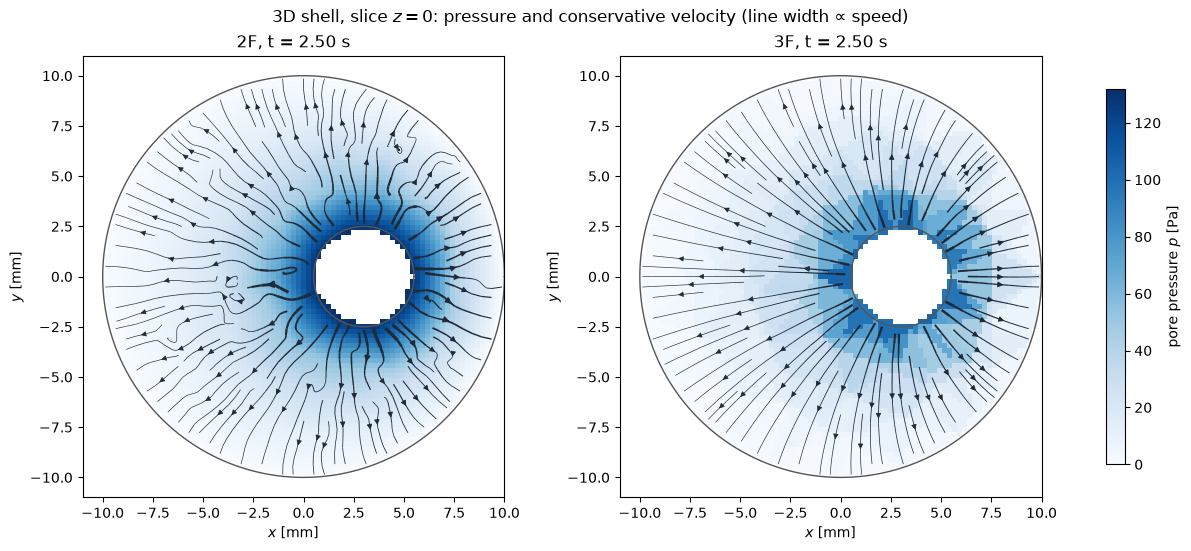

biot2: max p 132.0 Pa, max in-plane speed 851.6 µm/s
biot3: max p 105.7 Pa, max in-plane speed 370.2 µm/s


In [2]:
def on_slice(res, t):
    """x, y (mm), p (Pa) and in-plane cflux (µm/s) on the z = 0 slice at the snapshot nearest t."""
    i = np.argmin(np.abs(res["snap_t"] - t))
    xyz = res["slice_z0"]
    n = int(round(np.sqrt(len(xyz))))
    x, y = (xyz[:, k].reshape(n, n) * 1e3 for k in (0, 1))      # [i_y, i_x]
    p = res["slice_z0_p"][i].reshape(n, n)
    q = res["slice_z0_cflux"][i] * 1e6
    return x, y, p, q[:, 0].reshape(n, n), q[:, 1].reshape(n, n), res["snap_t"][i]


data = {m: on_slice(res, T) for m, res in r.items()}
pmax = max(np.nanmax(d[2]) for d in data.values())
smax = max(np.nanpercentile(np.hypot(d[3], d[4]), 99) for d in data.values())   # not the few hot cells at the cavity

fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), layout="constrained")
for ax, (m, (x, y, p, u, v, t)) in zip(axes, data.items()):
    im = ax.pcolormesh(x, y, p, cmap="Blues", vmin=0, vmax=pmax, shading="auto")
    speed = np.hypot(u, v)
    ax.streamplot(x[0], y[:, 0], u, v, color="#1f2a38", density=1.3, arrowsize=0.8,
                  linewidth=0.4 + 2.0 * np.minimum(np.nan_to_num(speed) / smax, 1))
    th = np.linspace(0, 2 * np.pi, 200)
    ax.plot(10 * np.cos(th), 10 * np.sin(th), color="#555", lw=1)               # outer wall
    ax.plot(3 + 2.5 * np.cos(th), 2.5 * np.sin(th), color="#555", lw=1)         # cavity
    ax.set_aspect("equal")
    ax.set(title=f"{'2F' if m == 'biot2' else '3F'}, t = {t:.2f} s", xlabel="$x$ [mm]", ylabel="$y$ [mm]")
fig.colorbar(im, ax=axes, shrink=0.85, label="pore pressure $p$ [Pa]")
fig.suptitle("3D shell, slice $z = 0$: pressure and conservative velocity (line width ∝ speed)")
plt.show()
for m, (x, y, p, u, v, t) in data.items():
    print(f"{m}: max p {np.nanmax(p):.1f} Pa, max in-plane speed {np.nanmax(np.hypot(u, v)):.1f} µm/s")